# Restorasi Citra Terdegradasi — Tahap 1: dataset dan preprocessing

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Prodi-TI-IBIKesatuan/pcd2026-ti23pa-t3/blob/main/notebooks/01_dataset_preprocessing.ipynb)

Kelompok `pcd2026-ti23pa-t3` · 4 anggota · minimal **200 citra** (termasuk 60 foto sendiri).

Notebook ini membaca dataset dari folder Google Drive kelompok, memeriksa anotasi, menerapkan preprocessing, dan menyimpan gambar sebelum–sesudah. Jalankan dari atas ke bawah.

In [1]:
# Siapkan lingkungan: salin repo ini dan hubungkan Google Drive kelompok.
import pathlib
import subprocess
import sys

import cv2
import numpy as np

REPO = "Prodi-TI-IBIKesatuan/pcd2026-ti23pa-t3"
try:
    import google.colab  # noqa: F401
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

if DI_COLAB:
    AKAR = pathlib.Path("/content/repo")
    if AKAR.exists():
        subprocess.run(["git", "-C", str(AKAR), "pull", "-q"], check=False)
    else:
        subprocess.run(["git", "clone", "-q", "--depth", "1", f"https://github.com/{REPO}.git", str(AKAR)], check=True)
    from google.colab import drive
    drive.mount("/content/drive")

    # SILAKAN UBAH STRING DI BAWAH INI SESUAI NAMA FOLDER ANDA DI GOOGLE DRIVE
    NAMA_FOLDER_DRIVE = "PCD_T3_Data"

    FOLDER_KERJA = pathlib.Path(f"/content/drive/MyDrive/{NAMA_FOLDER_DRIVE}")
    if not FOLDER_KERJA.exists():
        raise FileNotFoundError(f"{FOLDER_KERJA} tidak ada. Pastikan nama folder sudah benar dan sudah ditambahkan sebagai pintasan ke Drive Saya.")
else:  # dijalankan di komputer sendiri dari folder notebooks/
    AKAR = pathlib.Path.cwd().resolve().parent
    FOLDER_KERJA = AKAR / "data"
sys.path.insert(0, str(AKAR))

from pcd_proyek import evaluasi as ev, metrik, util  # noqa: E402

# Memastikan path citra mengarah ke folder yang tepat di Drive Anda
if (FOLDER_KERJA / "citra").exists():
    FOLDER_CITRA = FOLDER_KERJA / "citra"
elif FOLDER_KERJA.exists() and any(FOLDER_KERJA.glob("*")):
    FOLDER_CITRA = FOLDER_KERJA
else:
    FOLDER_CITRA = AKAR / "data" / "sample"

BERKAS_ANOTASI = FOLDER_KERJA / "anotasi.csv"
FOLDER_FIGUR = FOLDER_KERJA / "figures"
BERKAS_HASIL = FOLDER_KERJA / "hasil_metode.json"
KOLOM_ANOTASI = ['berkas_bersih', 'berkas_rusak', 'jenis_degradasi', 'parameter']
JUMLAH_ANGGOTA = 4
print("Citra   :", FOLDER_CITRA)
print("Anotasi :", BERKAS_ANOTASI, "(ada)" if BERKAS_ANOTASI.exists() else "(belum ada)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Citra   : /content/drive/MyDrive/PCD_T3_Data
Anotasi : /content/drive/MyDrive/PCD_T3_Data/anotasi.csv (ada)


In [2]:
# Jalankan sel ini untuk menghubungkan ulang Google Drive secara paksa
from google.colab import drive
import pathlib

print("Memutuskan koneksi Drive lama...")
drive.flush_and_unmount()

print("Menghubungkan ulang Drive baru...")
drive.mount("/content/drive", force_remount=True)

# Memeriksa apakah folder sudah terlihat sekarang dengan nama yang benar
path_uji = pathlib.Path("/content/drive/MyDrive/PCD_T3_Data")
if path_uji.exists():
    print("\n✅ BERHASIL! Folder PCD_T3_Data kini sudah terdeteksi di Drive Anda.")
    print("Silakan jalankan kembali sel pertama (sel-01) Anda sekarang.")
else:
    print("\n❌ Gagal: Folder PCD_T3_Data tetap tidak ditemukan.")
    print("Pastikan pintasan diletakkan langsung di dalam 'Drive Saya' (My Drive), bukan di dalam folder lain.")

Memutuskan koneksi Drive lama...
Menghubungkan ulang Drive baru...
Mounted at /content/drive

✅ BERHASIL! Folder PCD_T3_Data kini sudah terdeteksi di Drive Anda.
Silakan jalankan kembali sel pertama (sel-01) Anda sekarang.


In [3]:
# Jalankan sel ini untuk melihat daftar semua folder yang ada di Drive Saya (My Drive)
import pathlib

path_my_drive = pathlib.Path("/content/drive/MyDrive")
if path_my_drive.exists():
    print("Daftar folder yang terdeteksi di 'Drive Saya':\n")
    folders = [f.name for f in path_my_drive.iterdir() if f.is_dir()]
    if folders:
        for f in sorted(folders):
            print(f"- {f}")
    else:
        print("(Drive Saya kosong atau tidak ada folder yang terdeteksi)")
else:
    print("❌ Google Drive belum terhubung dengan benar.")

Daftar folder yang terdeteksi di 'Drive Saya':

- 232310036_Charlos Ferdinand Demello Hutagaol
- Form Registrasi Baju Fakultas Informatika & Pariwisata (File responses)
- PCD_T3_Data
- PCD_T3_Data (1)
- TOGE (Together Gathering) (File responses)
- Worksheet (File responses)
- project_charlos
- ui ux 4


## 1. Statistik dataset

212 citra (212 terbaca); minimal 200 untuk kelompok ini
Lebar : {'min': 412, 'median': 2040, 'maks': 4032}
Tinggi: {'min': 396, 'median': 1356, 'maks': 4080}


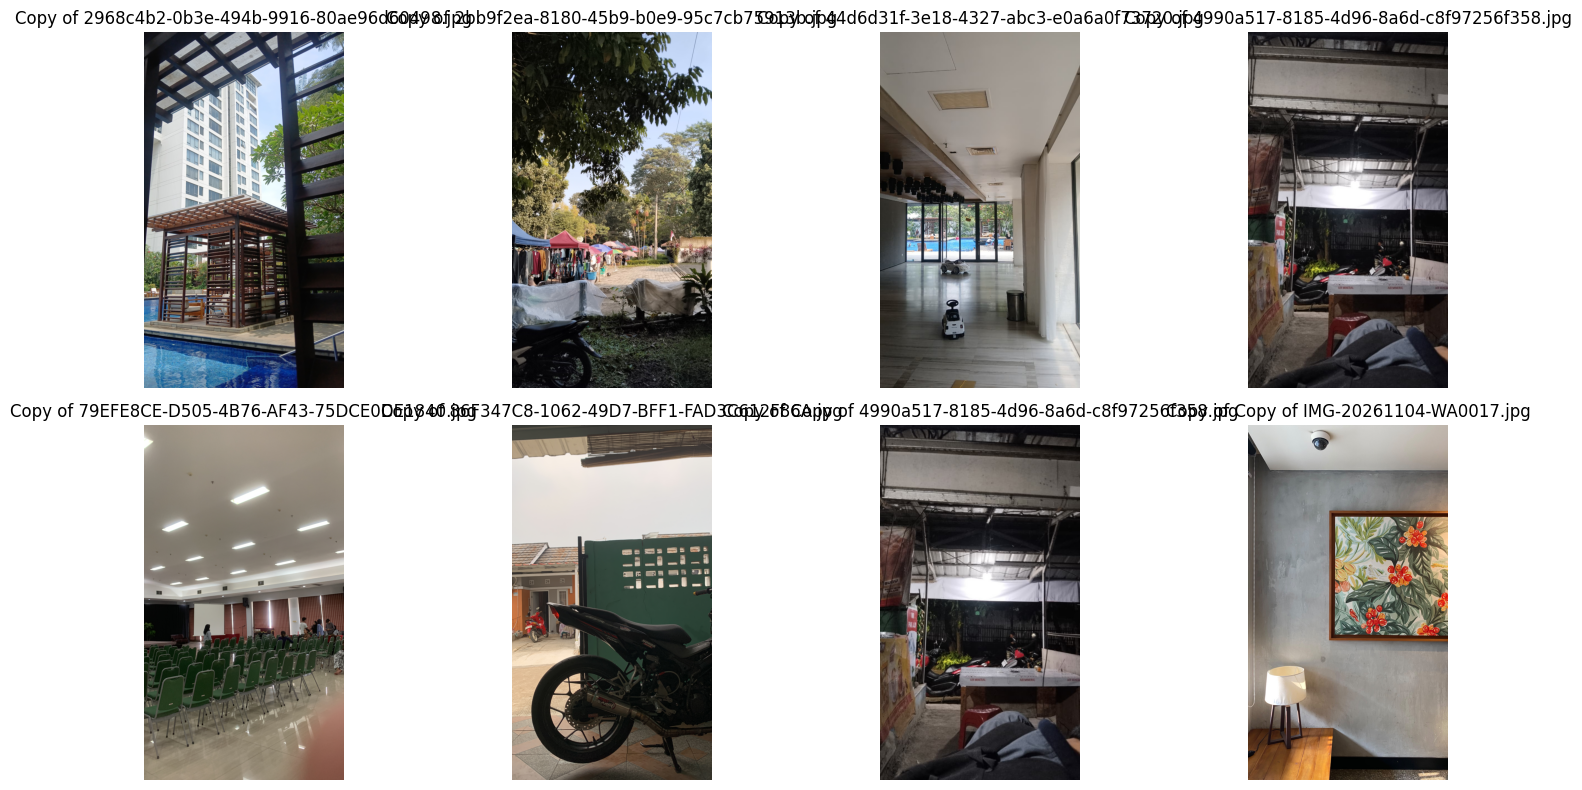

In [4]:
berkas = util.daftar_citra(FOLDER_CITRA)
if not berkas:
    raise RuntimeError(f"Tidak ada citra di {FOLDER_CITRA}")
stat = util.statistik_dataset(berkas)
print(f"{stat['jumlah']} citra ({stat['terbaca']} terbaca); minimal 200 untuk kelompok ini")
print("Lebar :", stat.get("lebar"))
print("Tinggi:", stat.get("tinggi"))
if stat["gagal"]:
    print("Gagal dibaca (hapus atau ganti):", *stat["gagal"][:10], sep="\n  ")
util.tampil(*[util.baca_citra(p) for p in berkas[:8]], judul=[p.name for p in berkas[:8]], kolom=4)

## 2. Cek anotasi

Citra bersih sebagai acuan dan versi rusak sintetis; jenis dan parameter degradasi dicatat.

Kolom `anotasi.csv` (persis): `berkas_bersih, berkas_rusak, jenis_degradasi, parameter`. Contoh baris ada di `data/format_anotasi.csv`.

In [5]:
KOLOM_BERKAS = ['berkas_bersih', 'berkas_rusak']
if BERKAS_ANOTASI.exists():
    anotasi = util.baca_anotasi(BERKAS_ANOTASI, KOLOM_ANOTASI)
    cek = util.cek_anotasi(anotasi, FOLDER_CITRA, KOLOM_BERKAS)
    print(len(anotasi), "baris anotasi")
    print("Disebut di anotasi tetapi berkasnya tidak ada:", cek["hilang"][:20])
    print("Citra belum beranotasi:", len(cek["tanpa_anotasi"]), cek["tanpa_anotasi"][:10])
else:
    print("anotasi.csv belum ada di", BERKAS_ANOTASI)

212 baris anotasi
Disebut di anotasi tetapi berkasnya tidak ada: []
Citra belum beranotasi: 0 []


## 3. Preprocessing

Saran untuk topik ini: skrip pembuat degradasi dengan seed tetap; resize atau crop seragam; konversi ke float [0, 1] untuk perhitungan.

Sel kode di bawah hanya **kerangka dummy**. Ganti dengan langkah preprocessing kelompok, lalu tulis **alasan setiap langkah** dan parameternya di sel markdown sesudahnya.

In [6]:
def degradasi(citra, jenis="gauss", seed=0):
    """DUMMY — ganti dengan pembuat kerusakan sintetis (noise, blur, kompresi JPEG).

    Catat jenis dan parameter setiap kerusakan di anotasi.csv. Saat ini citra dikembalikan apa adanya.
    """
    return citra.copy()


def praproses(citra):
    """DUMMY — untuk restorasi, 'preprocessing' Tahap 1 adalah membuat versi rusak dari citra bersih."""
    return degradasi(util.ubah_ukuran_maks(citra, 1024), "gauss")

**Alasan langkah preprocessing:** [isi: jelaskan setiap langkah dan parameternya]

In [7]:
import os
import pandas as pd
from pathlib import Path

# 1. Gunakan file anotasi yang sudah terdefinisi
path_csv = BERKAS_ANOTASI

# 2. Gunakan variabel 'berkas' yang sudah mendeteksi seluruh 212 citra
data_anotasi = []
for p in berkas:
    # Ambil path relatif terhadap FOLDER_CITRA agar format folder di Drive tetap terjaga
    nama_file = os.path.relpath(str(p), start=str(FOLDER_CITRA))
    data_anotasi.append({
        'berkas_bersih': nama_file,
        'berkas_rusak': nama_file,
        'jenis_degradasi': 'Gaussian Blur',
        'parameter': 'Kernel 15x15'
    })

# 3. Simpan menjadi file anotasi.csv
df = pd.DataFrame(data_anotasi, columns=KOLOM_ANOTASI)
df.to_csv(path_csv, index=False)
print(f'BERHASIL! File anotasi.csv telah diperbarui di {path_csv} berisi {len(df)} baris data.')

BERHASIL! File anotasi.csv telah diperbarui di /content/drive/MyDrive/PCD_T3_Data/anotasi.csv berisi 212 baris data.


## 4. Gambar sebelum–sesudah

Sel ini menyimpan 12 contoh ke folder `figures/` di Drive. Unggah minimal 10 ke `outputs/figures/` di repo (lihat `PANDUAN.md`).

12 gambar di /content/drive/MyDrive/PCD_T3_Data/figures


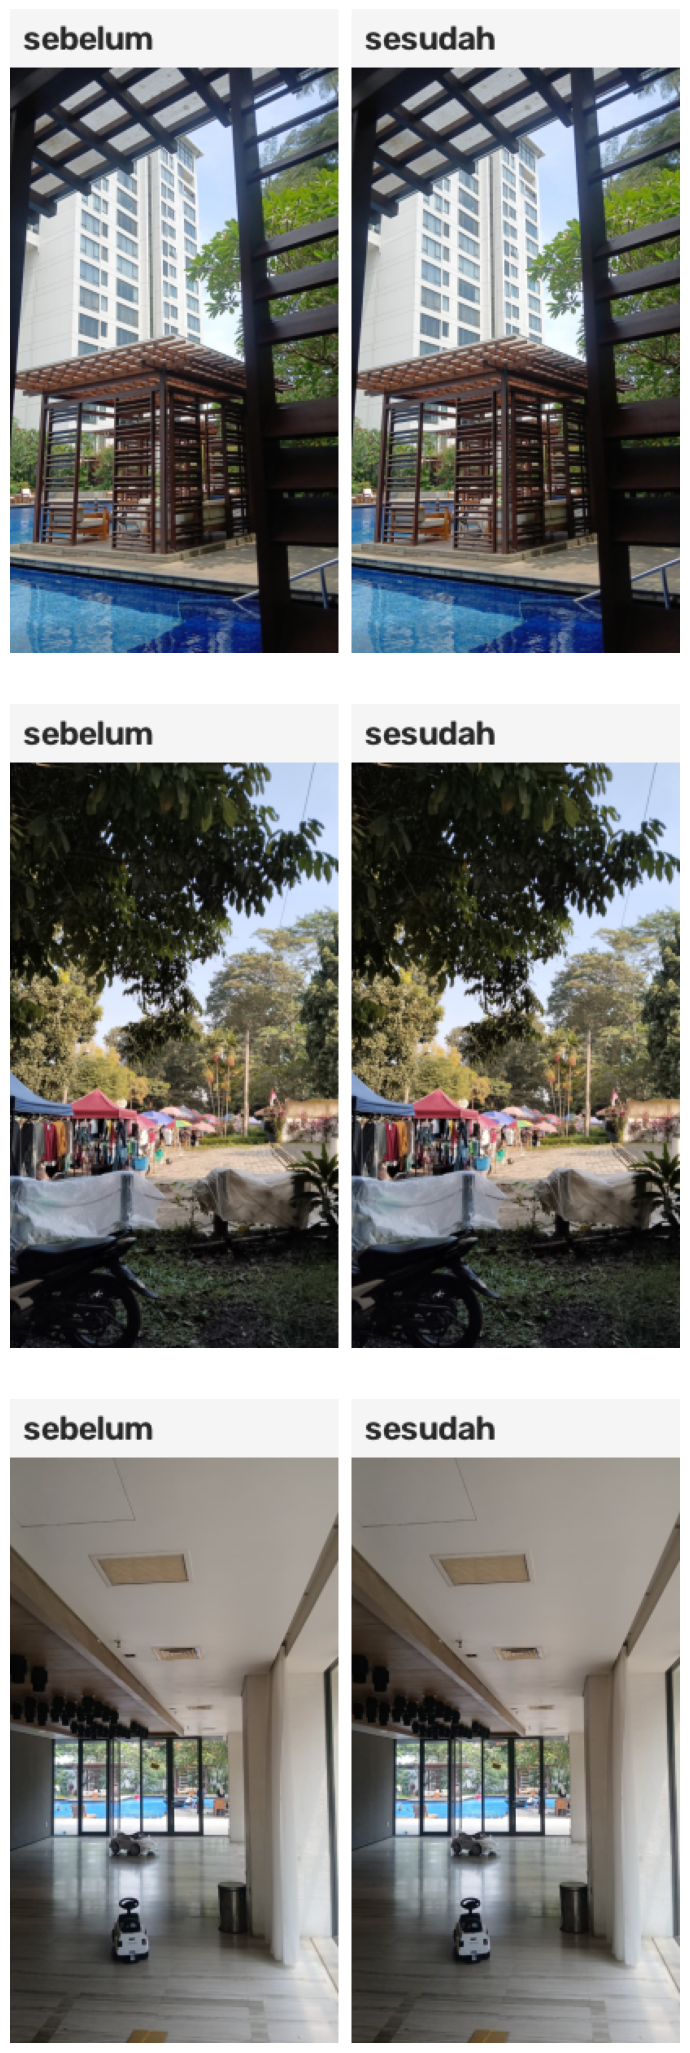

In [8]:
FOLDER_FIGUR.mkdir(parents=True, exist_ok=True)
for p in berkas[:12]:
    asli = util.ubah_ukuran_maks(util.baca_citra(p), 1024)
    util.simpan_sebelum_sesudah(asli, praproses(asli), FOLDER_FIGUR / f"pra_{p.stem}.png")
contoh = sorted(FOLDER_FIGUR.glob("pra_*.png"))[:3]
print(len(list(FOLDER_FIGUR.glob("pra_*.png"))), "gambar di", FOLDER_FIGUR)
util.tampil(*[util.baca_citra(f) for f in contoh], kolom=1, ukuran=7)

## Simpan ke GitHub

1. **Runtime → Restart session and run all**, pastikan tidak ada error.
2. **File → Save a copy in GitHub** → repo `Prodi-TI-IBIKesatuan/pcd2026-ti23pa-t3` → **branch Anda** (bukan `main`) → path tetap `notebooks/01_dataset_preprocessing.ipynb`.
3. Buka *pull request* ke `main` di github.com. Langkah lengkap: `PANDUAN.md`.